# End-to-End Customer Analytics & Revenue Forecasting using Python
Tools: Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn


## 1. Problem Statement

**Business context:** A subscription-based digital services company collects customer demographic, subscription, usage and marketing data, but has not yet used it fully for decision-making. The company wants to understand customer behavior, increase revenue and reduce churn.

**Objective:**
1. Clean and prepare the raw customer subscription data
2. Engineer meaningful features that capture customer behavior and value
3. Analyze the patterns that influence revenue and churn
4. Build a predictive Linear Regression model to estimate customer revenue

**Key business questions:**
- Which customer characteristics contribute most to revenue?
- How do tenure, plan type, discounts and usage affect revenue?
- Are some customer segments more valuable than others?
- Can we reliably predict revenue using historical data?

**Expected outcome:** A clean, analysis-ready dataset, actionable business insights, and a revenue prediction model for strategic planning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("subscription_data - subscription_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (2560, 15)


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
0,10001,56.0,Female,Chennai,12/3/2022,12/29/2022,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90
1,10002,46.0,Female,Mumbai,3/24/2021,1/25/2022,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40
2,10003,32.0,Female,Mumbai,6/15/2023,8/10/2023,Basic,783,4,0,41.93,5.0,Referral,No,3092.85
3,10004,60.0,Male,Delhi,11/13/2022,7/8/2021,Standard,545,4,1,116.41,0.0,Organic,No,2180.00
4,10005,25.0,Female,Mumbai,2/17/2022,6/25/2021,Basic,1331,30,1,81.89,10.0,Ads,No,39796.90


## 2. Data Understanding

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 2560
Columns: 15


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2560 entries, 0 to 2559
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        2560 non-null   int64  
 1   age                2455 non-null   float64
 2   gender             2560 non-null   object 
 3   city               2456 non-null   object 
 4   signup_date        2560 non-null   object 
 5   last_active_date   2560 non-null   object 
 6   plan_type          2560 non-null   object 
 7   monthly_fee        2560 non-null   int64  
 8   tenure_months      2560 non-null   int64  
 9   support_tickets    2560 non-null   int64  
 10  avg_session_time   2459 non-null   float64
 11  discount_percent   2455 non-null   float64
 12  marketing_channel  2560 non-null   object 
 13  churned            2560 non-null   object 
 14  total_revenue      2560 non-null   float64
dtypes: float64(4), int64(4), object(7)
memory usage: 300.1+ KB


In [5]:
df.isnull().sum()

,0
customer_id,0
age,105
gender,0
city,104
signup_date,0
last_active_date,0
plan_type,0
monthly_fee,0
tenure_months,0
support_tickets,0


In [6]:
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_pct[missing_pct > 0].sort_values(ascending=False)

,0
age,4.10
discount_percent,4.10
city,4.06
avg_session_time,3.95


**Observations:**
- The dataset has 2560 rows and 15 columns.
- Age, city, avg_session_time and discount_percent have about 4% missing values.
- Date columns are stored as text and need to be converted to datetime.


In [7]:
## 3. Data Cleaning
### 3.1 Handling Missing Values

In [8]:
df_clean = df.copy()

In [9]:
print(df_clean[["age", "avg_session_time", "discount_percent"]].describe().round(2))
print("\nSkewness:")
print(df_clean[["age", "avg_session_time", "discount_percent"]].skew().round(2))

           age  avg_session_time  discount_percent
count  2455.00           2459.00           2455.00
mean     41.16             62.72             10.02
std      13.56             32.92              7.10
min      18.00              5.13              0.00
25%      29.00             34.57              5.00
50%      41.00             62.59             10.00
75%      53.00             90.65             15.00
max      64.00            119.94             20.00

Skewness:
age                -0.02
avg_session_time    0.01
discount_percent    0.00
dtype: float64


In [10]:
# Q5: age -> median (numeric, not affected by outliers)
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())

# Q6: city -> "Unknown" (categorical, so we don't guess a city)
df_clean["city"] = df_clean["city"].fillna("Unknown")

# Q7: avg_session_time -> median
df_clean["avg_session_time"] = df_clean["avg_session_time"].fillna(df_clean["avg_session_time"].median())

# Q8: discount_percent -> median
df_clean["discount_percent"] = df_clean["discount_percent"].fillna(df_clean["discount_percent"].median())

In [11]:
df_clean.isnull().sum()

,0
customer_id,0
age,0
gender,0
city,0
signup_date,0
last_active_date,0
plan_type,0
monthly_fee,0
tenure_months,0
support_tickets,0


**Observation:** Missing values in age, avg_session_time and discount_percent were filled with the median. City was filled with "Unknown". The dataset now has no missing values.

### 3.2 Handling Duplicate Records

In [12]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate customer_id:", df_clean["customer_id"].duplicated().sum())

Duplicate rows: 60
Duplicate customer_id: 60


In [13]:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df_clean.shape)

Shape after removing duplicates: (2500, 15)


### 3.3 Fixing Date Columns

In [14]:
df_clean["signup_date"] = pd.to_datetime(df_clean["signup_date"], format="%m/%d/%Y")
df_clean["last_active_date"] = pd.to_datetime(df_clean["last_active_date"], format="%m/%d/%Y")

df_clean[["signup_date", "last_active_date"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   signup_date       2500 non-null   datetime64[ns]
 1   last_active_date  2500 non-null   datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 39.2 KB


In [15]:
illogical = df_clean["last_active_date"] < df_clean["signup_date"]
print("Records where last active is before signup:", illogical.sum())
print("Percentage:", round(illogical.mean() * 100, 2), "%")
df_clean[illogical].head()

Records where last active is before signup: 852
Percentage: 34.08 %


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
3,10004,60.0,Male,Delhi,2022-11-13,2021-07-08,Standard,545,4,1,116.41,0.0,Organic,No,2180.00
4,10005,25.0,Female,Mumbai,2022-02-17,2021-06-25,Basic,1331,30,1,81.89,10.0,Ads,No,39796.90
6,10007,56.0,Male,Hyderabad,2022-12-01,2022-09-04,Basic,510,29,4,118.63,0.0,Referral,Yes,14790.00
8,10009,40.0,Male,Bangalore,2023-03-12,2022-07-22,Basic,1243,21,2,59.75,15.0,Organic,Yes,25916.55
10,10011,28.0,Female,Delhi,2022-09-01,2022-06-18,Basic,1378,4,2,11.39,20.0,Email,No,5236.40


Duplicate rows: 60
duplicate customer_id: 60
Shape after removing duplicates: (2500, 15)
Illogical dates: 852, about 34%

In [16]:
mask = df_clean["last_active_date"] < df_clean["signup_date"]

df_clean.loc[mask, ["signup_date", "last_active_date"]] = (
    df_clean.loc[mask, ["last_active_date", "signup_date"]].values
)

print("Illogical dates remaining:",
      (df_clean["last_active_date"] < df_clean["signup_date"]).sum())

Illogical dates remaining: 0


**Observation:** 60 duplicate records were removed (2560 → 2500 rows). Date columns were converted to datetime. 852 records had last_active_date before signup_date, so the two dates were swapped, assuming a data-entry error. Dropping them would have removed about 34% of the data.

why swap instead of drop?”,
answer:
“Dropping would lose a third of the data, and the pattern suggested the dates were entered in the wrong columns. I documented the assumption. In a real project I would confirm with the data owner.”

### 3.4 Checking Invalid Age Values

In [17]:
invalid_age = df_clean[(df_clean["age"] < 18) | (df_clean["age"] > 80)]
print("Invalid age records:", len(invalid_age))
print("Age range:", df_clean["age"].min(), "to", df_clean["age"].max())

Invalid age records: 0
Age range: 18.0 to 64.0


## 4. Feature Engineering

In [18]:
# Q15: tenure in years
df_clean["customer_tenure_years"] = (df_clean["tenure_months"] / 12).round(2)

# Q16: revenue per month
df_clean["revenue_per_month"] = (df_clean["total_revenue"] / df_clean["tenure_months"]).round(2)

# Q17: binary churn flag (1 = churned, 0 = active)
df_clean["churn_flag"] = df_clean["churned"].map({"Yes": 1, "No": 0})

# Q18: age group
df_clean["age_group"] = np.where(df_clean["age"] < 25, "Young",
                         np.where(df_clean["age"] < 45, "Middle", "Senior"))

# Q19: high-value customer (revenue above the median)
median_rev = df_clean["total_revenue"].median()
df_clean["high_value_customer"] = np.where(df_clean["total_revenue"] > median_rev, "Yes", "No")

# Q20: days active
df_clean["days_active"] = (df_clean["last_active_date"] - df_clean["signup_date"]).dt.days

In [19]:
df_clean[["tenure_months", "customer_tenure_years", "total_revenue", "revenue_per_month",
          "churned", "churn_flag", "age", "age_group",
          "high_value_customer", "days_active"]].head(10)

,tenure_months,customer_tenure_years,total_revenue,revenue_per_month,churned,churn_flag,age,age_group,high_value_customer,days_active
0,25,2.08,30167.90,1206.72,Yes,1,56.0,Senior,Yes,26
1,22,1.83,27642.40,1256.47,Yes,1,46.0,Senior,Yes,307
2,4,0.33,3092.85,773.21,No,0,32.0,Middle,No,56
3,4,0.33,2180.00,545.00,No,0,60.0,Senior,No,493
4,30,2.50,39796.90,1326.56,No,0,25.0,Middle,Yes,237
5,2,0.17,834.35,417.18,No,0,38.0,Middle,No,394
6,29,2.42,14790.00,510.00,Yes,1,56.0,Senior,Yes,88
7,21,1.75,13886.10,661.24,No,0,36.0,Middle,Yes,553
8,21,1.75,25916.55,1234.12,Yes,1,40.0,Middle,Yes,233
9,21,1.75,8027.25,382.25,No,0,28.0,Middle,No,279


In [20]:
print(df_clean["churn_flag"].value_counts())
print()
print(df_clean["age_group"].value_counts())
print()
print(df_clean["high_value_customer"].value_counts())

churn_flag
0    1914
1     586
Name: count, dtype: int64

age_group
Middle    1112
Senior    1038
Young      350
Name: count, dtype: int64

high_value_customer
Yes    1250
No     1250
Name: count, dtype: int64


**Observation:** No invalid ages were found (range 18-64). Six new features were created: tenure in years, revenue per month, churn flag, age group, high-value flag and days active.

In [21]:
# Q21: session usage category
df_clean["session_usage_category"] = np.where(df_clean["avg_session_time"] < 30, "Low",
                                     np.where(df_clean["avg_session_time"] < 60, "Medium", "High"))

# Q22: discount category
df_clean["discount_category"] = np.where(df_clean["discount_percent"] == 0, "No Discount",
                                np.where(df_clean["discount_percent"] <= 10, "Low Discount", "High Discount"))

# Q23 and Q24: signup month and year
df_clean["signup_month"] = df_clean["signup_date"].dt.month
df_clean["signup_year"] = df_clean["signup_date"].dt.year

# Q25: support intensity
df_clean["support_intensity"] = np.where(df_clean["support_tickets"] >= 5, "High", "Low")

# Q26: revenue category
df_clean["revenue_category"] = np.where(df_clean["total_revenue"] < 10000, "Low",
                               np.where(df_clean["total_revenue"] < 30000, "Medium", "High"))

# Q27: plan rank for modeling
df_clean["plan_rank"] = df_clean["plan_type"].map({"Basic": 1, "Standard": 2, "Premium": 3})

# Q28: engagement score
df_clean["engagement_score"] = (df_clean["avg_session_time"] / (df_clean["support_tickets"] + 1)).round(2)

In [22]:
df_clean[["avg_session_time", "session_usage_category", "discount_percent", "discount_category",
          "signup_date", "signup_month", "signup_year", "support_tickets", "support_intensity",
          "total_revenue", "revenue_category", "plan_type", "plan_rank",
          "engagement_score"]].head(10)

,avg_session_time,session_usage_category,discount_percent,discount_category,signup_date,signup_month,signup_year,support_tickets,support_intensity,total_revenue,revenue_category,plan_type,plan_rank,engagement_score
0,15.75,Low,15.0,High Discount,2022-12-03,12,2022,5,High,30167.90,High,Basic,1,2.62
1,37.16,Medium,20.0,High Discount,2021-03-24,3,2021,1,Low,27642.40,Medium,Premium,3,18.58
2,41.93,Medium,5.0,Low Discount,2023-06-15,6,2023,0,Low,3092.85,Low,Basic,1,41.93
3,116.41,High,0.0,No Discount,2021-07-08,7,2021,1,Low,2180.00,Low,Standard,2,58.20
4,81.89,High,10.0,Low Discount,2021-06-25,6,2021,1,Low,39796.90,High,Basic,1,40.94
5,53.99,Medium,15.0,High Discount,2021-06-16,6,2021,0,Low,834.35,Low,Standard,2,53.99
6,118.63,High,0.0,No Discount,2022-09-04,9,2022,4,Low,14790.00,Medium,Basic,1,23.73
7,22.62,Low,15.0,High Discount,2021-06-18,6,2021,1,Low,13886.10,Medium,Basic,1,11.31
8,59.75,Medium,15.0,High Discount,2022-07-22,7,2022,2,Low,25916.55,Medium,Basic,1,19.92
9,79.41,High,15.0,High Discount,2021-08-17,8,2021,4,Low,8027.25,Low,Basic,1,15.88


In [23]:
for col in ["session_usage_category", "discount_category", "support_intensity",
            "revenue_category", "plan_rank"]:
    print(df_clean[col].value_counts())
    print()

session_usage_category
High      1345
Medium     655
Low        500
Name: count, dtype: int64

discount_category
Low Discount     1065
High Discount     958
No Discount       477
Name: count, dtype: int64

support_intensity
Low     2332
High     168
Name: count, dtype: int64

revenue_category
Medium    1206
Low        957
High       337
Name: count, dtype: int64

plan_rank
1    1101
2     910
3     489
Name: count, dtype: int64



In [24]:
print("Final shape:", df_clean.shape)
df_clean.isnull().sum().sum()

Final shape: (2500, 29)


np.int64(0)

engagement_score = avg_session_time ÷ (support_tickets + 1)

**Observation:** Features were created for usage, discounts, support intensity, revenue category, signup month/year, plan rank and engagement score. The final dataset has 2500 rows and 29 columns with no missing values, ready for analysis.

In [25]:
df_clean.to_csv("cleaned_customer_data.csv", index=False)

## 5. Exploratory Data Analysis (EDA)
### 5.1 Data Understanding and Distribution

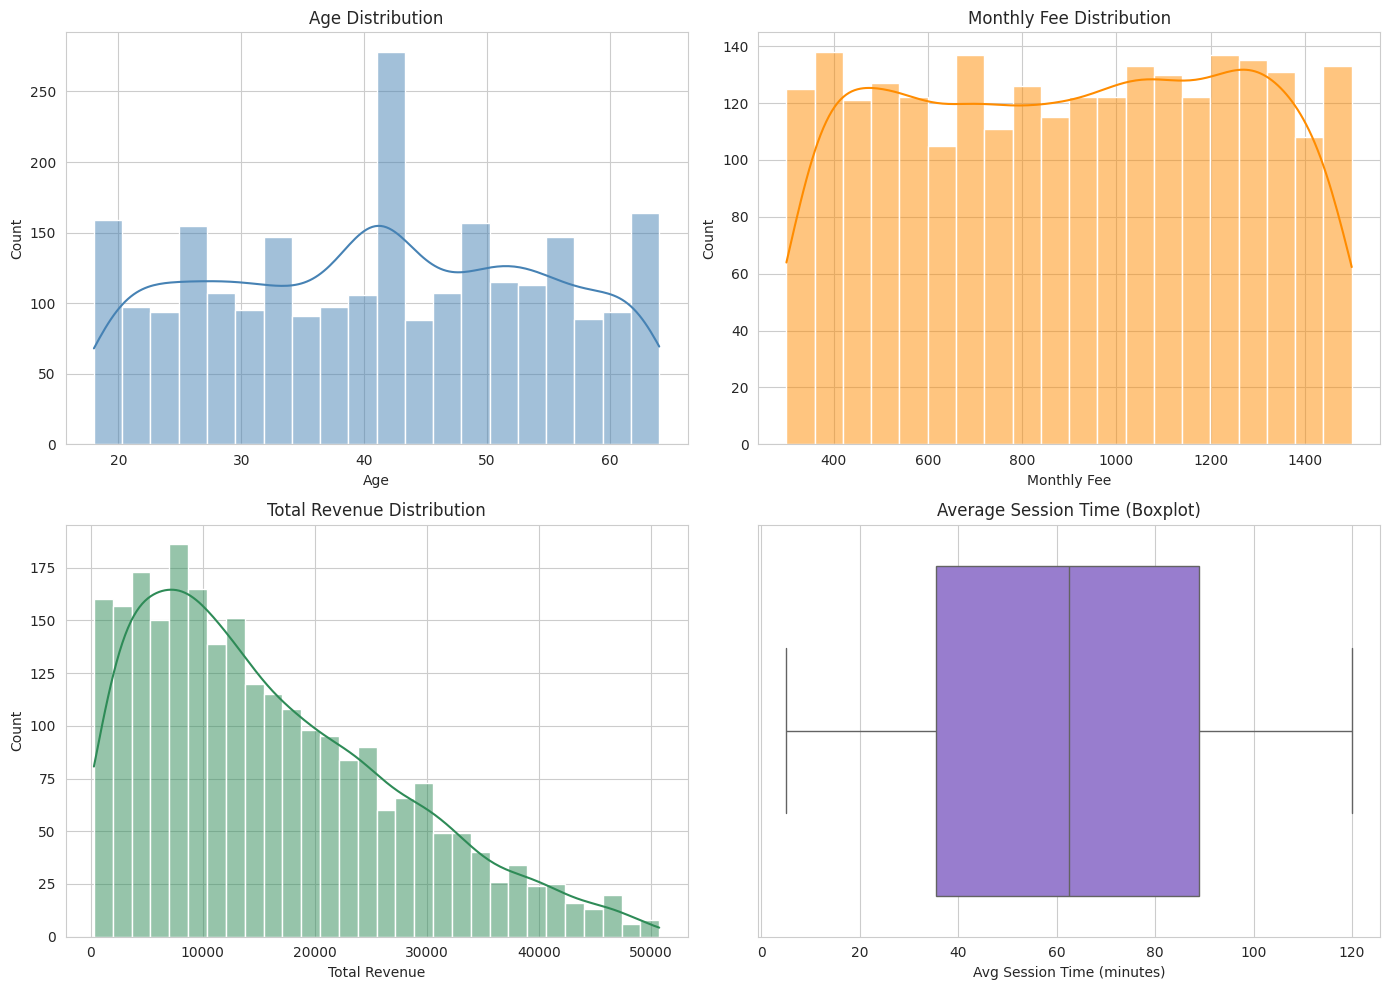

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Age distribution
sns.histplot(df_clean["age"], bins=20, kde=True, color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Age Distribution")
axes[0, 0].set_xlabel("Age")

# 2. Monthly fee distribution
sns.histplot(df_clean["monthly_fee"], bins=20, kde=True, color="darkorange", ax=axes[0, 1])
axes[0, 1].set_title("Monthly Fee Distribution")
axes[0, 1].set_xlabel("Monthly Fee")

# 3. Total revenue distribution
sns.histplot(df_clean["total_revenue"], bins=30, kde=True, color="seagreen", ax=axes[1, 0])
axes[1, 0].set_title("Total Revenue Distribution")
axes[1, 0].set_xlabel("Total Revenue")

# 4. Avg session time boxplot
sns.boxplot(x=df_clean["avg_session_time"], color="mediumpurple", ax=axes[1, 1])
axes[1, 1].set_title("Average Session Time (Boxplot)")
axes[1, 1].set_xlabel("Avg Session Time (minutes)")

plt.tight_layout()
plt.show()

In [27]:
print("Skewness:")
print(df_clean[["age", "monthly_fee", "total_revenue", "avg_session_time"]].skew().round(2))
print()
print(df_clean[["age", "monthly_fee", "total_revenue", "avg_session_time"]].describe().round(2))

Skewness:
age                -0.02
monthly_fee        -0.03
total_revenue       0.76
avg_session_time    0.02
dtype: float64

           age  monthly_fee  total_revenue  avg_session_time
count  2500.00      2500.00        2500.00           2500.00
mean     41.13       902.54       15909.88             62.65
std      13.29       348.08       11366.85             32.24
min      18.00       300.00         288.15              5.13
25%      30.00       593.00        6889.05             35.48
50%      41.00       911.50       13457.82             62.59
75%      52.00      1205.00       23251.38             88.90
max      64.00      1499.00       50741.60            119.94


**Observations:**
- Customers range from 18 to 64 years old. The spike near age 42 comes from filling missing ages with the median.
- Monthly fees are spread fairly evenly between 300 and 1500.
- Total revenue is right-skewed: most customers generate lower revenue, while a smaller group generates much higher revenue.
- Average session time has a median of about 62 minutes and no outliers.

### 5.2 Categorical Insights

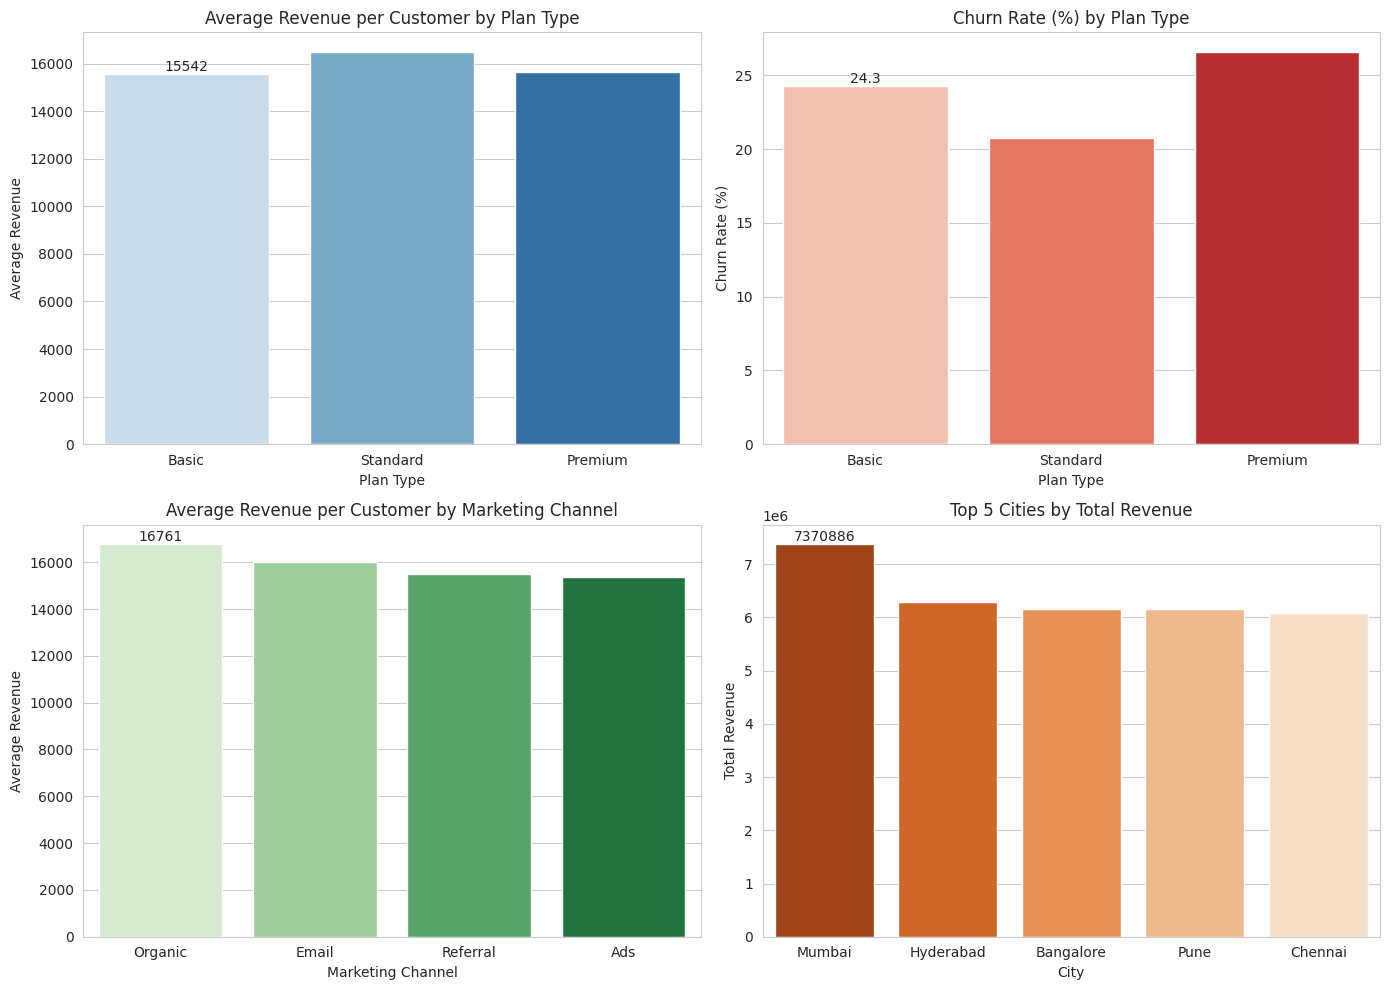

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 5. Average revenue per customer by plan type
plan_rev = df_clean.groupby("plan_type")["total_revenue"].mean().reindex(["Basic", "Standard", "Premium"]).reset_index()
sns.barplot(data=plan_rev, x="plan_type", y="total_revenue", hue="plan_type", legend=False,
            palette="Blues", ax=axes[0, 0])
axes[0, 0].set_title("Average Revenue per Customer by Plan Type")
axes[0, 0].set_xlabel("Plan Type")
axes[0, 0].set_ylabel("Average Revenue")
axes[0, 0].bar_label(axes[0, 0].containers[0], fmt="%.0f")

# 6. Churn rate by plan type
plan_churn = (df_clean.groupby("plan_type")["churn_flag"].mean() * 100).reindex(["Basic", "Standard", "Premium"]).reset_index()
sns.barplot(data=plan_churn, x="plan_type", y="churn_flag", hue="plan_type", legend=False,
            palette="Reds", ax=axes[0, 1])
axes[0, 1].set_title("Churn Rate (%) by Plan Type")
axes[0, 1].set_xlabel("Plan Type")
axes[0, 1].set_ylabel("Churn Rate (%)")
axes[0, 1].bar_label(axes[0, 1].containers[0], fmt="%.1f")

# 7. Average revenue per customer by marketing channel
chan_rev = df_clean.groupby("marketing_channel")["total_revenue"].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=chan_rev, x="marketing_channel", y="total_revenue", hue="marketing_channel", legend=False,
            palette="Greens", ax=axes[1, 0])
axes[1, 0].set_title("Average Revenue per Customer by Marketing Channel")
axes[1, 0].set_xlabel("Marketing Channel")
axes[1, 0].set_ylabel("Average Revenue")
axes[1, 0].bar_label(axes[1, 0].containers[0], fmt="%.0f")

# 8. Top 5 cities by total revenue (excluding Unknown)
city_rev = (df_clean[df_clean["city"] != "Unknown"]
            .groupby("city")["total_revenue"].sum().sort_values(ascending=False).head(5).reset_index())
sns.barplot(data=city_rev, x="city", y="total_revenue", hue="city", legend=False,
            palette="Oranges_r", ax=axes[1, 1])
axes[1, 1].set_title("Top 5 Cities by Total Revenue")
axes[1, 1].set_xlabel("City")
axes[1, 1].set_ylabel("Total Revenue")
axes[1, 1].bar_label(axes[1, 1].containers[0], fmt="%.0f")

plt.tight_layout()
plt.show()

In [29]:
print(df_clean.groupby("plan_type").agg(customers=("customer_id", "count"),
                                        avg_revenue=("total_revenue", "mean"),
                                        churn_rate=("churn_flag", "mean")).round(3))
print()
print(df_clean.groupby("marketing_channel")["total_revenue"].agg(["mean", "sum"]).round(0))

           customers  avg_revenue  churn_rate
plan_type                                    
Basic           1101    15541.817       0.243
Premium          489    15659.452       0.266
Standard         910    16489.777       0.208

                      mean         sum
marketing_channel                     
Ads                15367.0   9358576.0
Email              16022.0  10446037.0
Organic            16761.0  10089889.0
Referral           15511.0   9880207.0


**Observations:**
- Standard plan has the highest average revenue per customer, but the differences between plans are small.
- Premium has the highest churn rate (~26.6%) and Standard the lowest (~20.8%).
- Organic customers bring the highest average revenue; Ads the lowest.
- Mumbai contributes the most total revenue, well ahead of the other top cities.

### 5.3 Behavioral and Time-Based Trends

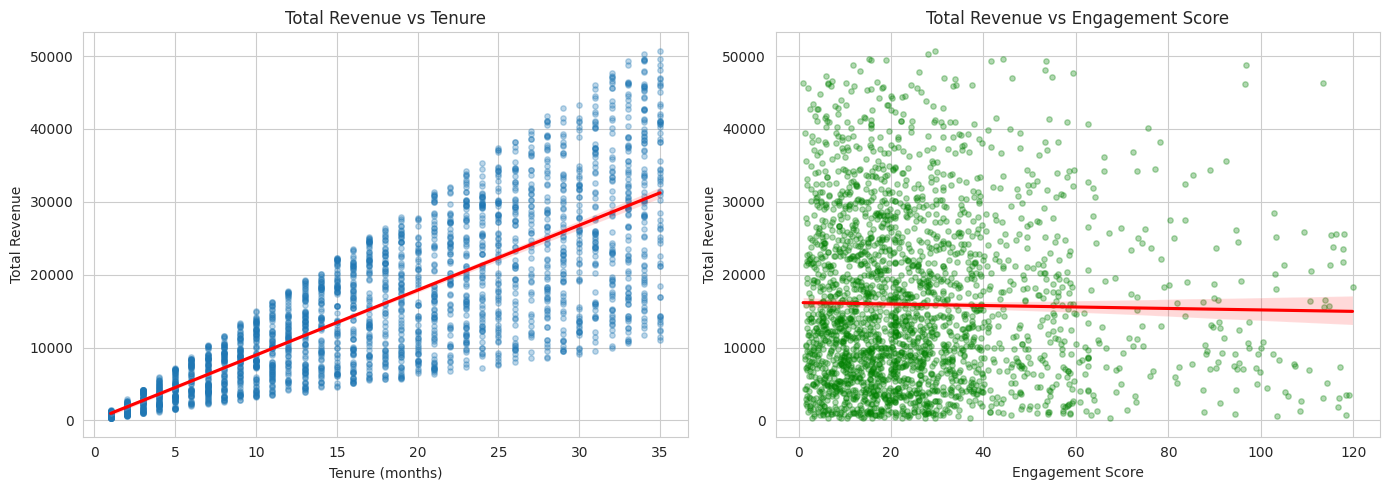

Correlation (revenue vs tenure): 0.79
Correlation (revenue vs engagement): -0.02


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 9. Revenue vs tenure
sns.regplot(data=df_clean, x="tenure_months", y="total_revenue",
            scatter_kws={"alpha": 0.3, "s": 15}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title("Total Revenue vs Tenure")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Total Revenue")

# 10. Engagement score vs revenue
sns.regplot(data=df_clean, x="engagement_score", y="total_revenue",
            scatter_kws={"alpha": 0.3, "s": 15, "color": "green"}, line_kws={"color": "red"}, ax=axes[1])
axes[1].set_title("Total Revenue vs Engagement Score")
axes[1].set_xlabel("Engagement Score")
axes[1].set_ylabel("Total Revenue")

plt.tight_layout()
plt.show()

print("Correlation (revenue vs tenure):", round(df_clean["total_revenue"].corr(df_clean["tenure_months"]), 2))
print("Correlation (revenue vs engagement):", round(df_clean["total_revenue"].corr(df_clean["engagement_score"]), 2))

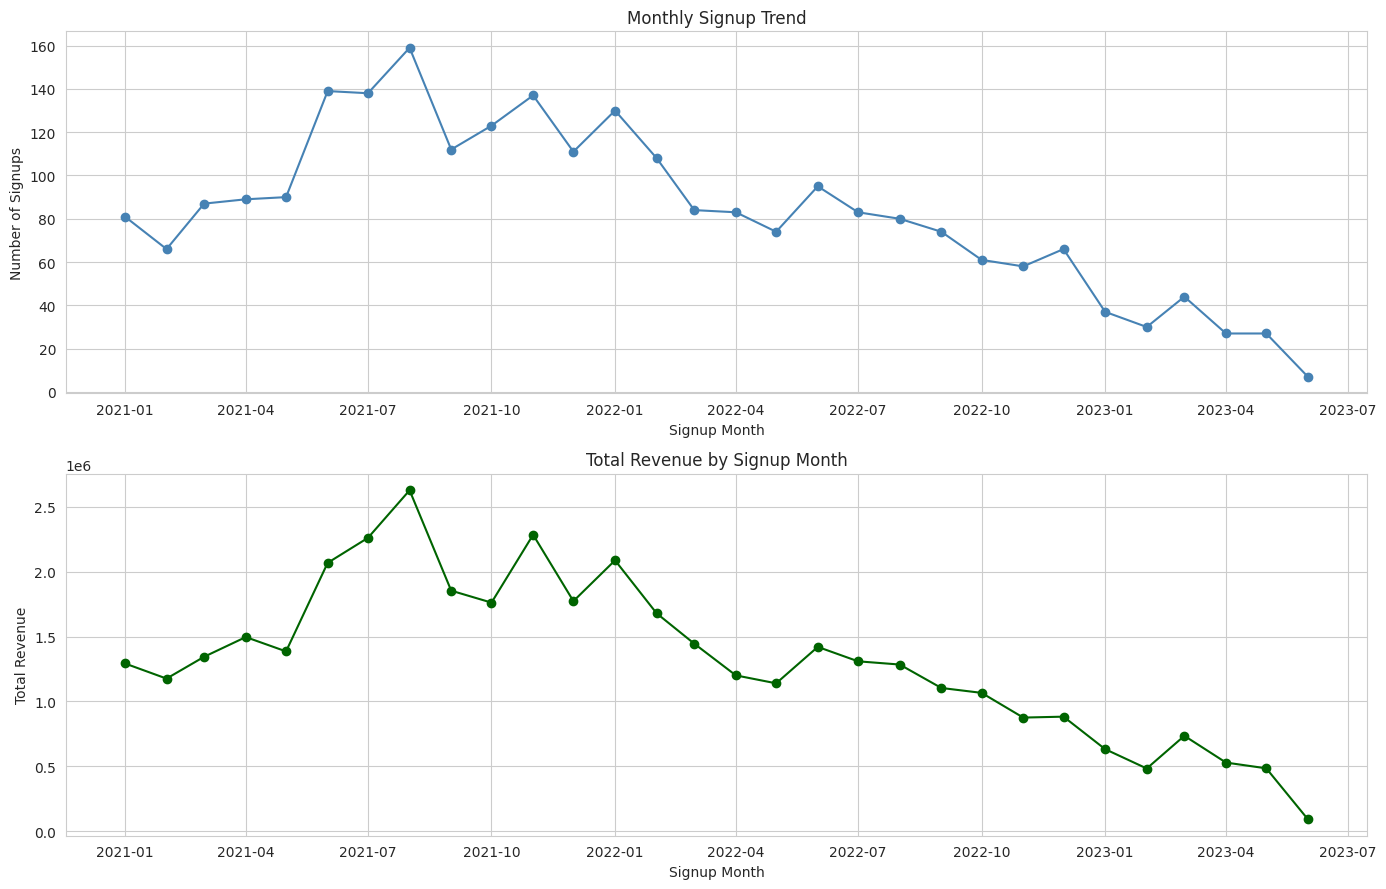

In [31]:
monthly = df_clean.groupby(df_clean["signup_date"].dt.to_period("M")).agg(
    signups=("customer_id", "count"),
    revenue=("total_revenue", "sum")
)
monthly.index = monthly.index.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# 11. Signup trend
axes[0].plot(monthly.index, monthly["signups"], marker="o", color="steelblue")
axes[0].set_title("Monthly Signup Trend")
axes[0].set_xlabel("Signup Month")
axes[0].set_ylabel("Number of Signups")

# 12. Monthly revenue trend (by signup month)
axes[1].plot(monthly.index, monthly["revenue"], marker="o", color="darkgreen")
axes[1].set_title("Total Revenue by Signup Month")
axes[1].set_xlabel("Signup Month")
axes[1].set_ylabel("Total Revenue")

plt.tight_layout()
plt.show()

**Observations:**
- Revenue rises strongly with tenure (correlation 0.79): longer-staying customers generate more revenue.
- Engagement score shows almost no relationship with revenue (correlation about -0.02).
- Monthly signups peaked around mid-2021 and have declined since, falling sharply by 2023. The latest month is incomplete.
- Revenue by signup month follows the same pattern as signups.
- Recommendation: focus on retaining customers longer and on re-boosting acquisition.

### 5.4 Modeling Support: Correlation Heatmap

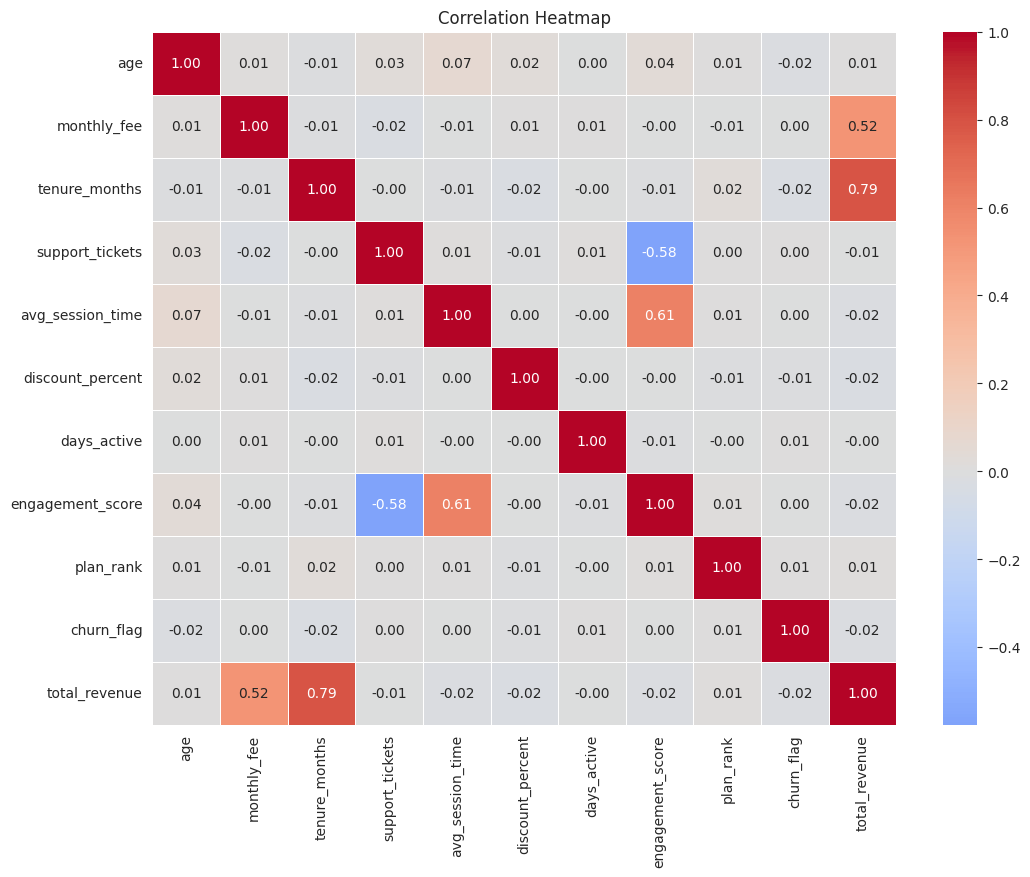

In [32]:
corr_cols = ["age", "monthly_fee", "tenure_months", "support_tickets", "avg_session_time",
             "discount_percent", "days_active", "engagement_score", "plan_rank",
             "churn_flag", "total_revenue"]

corr_matrix = df_clean[corr_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

In [33]:
corr_matrix["total_revenue"].drop("total_revenue").sort_values(ascending=False).round(2)

,total_revenue
tenure_months,0.79
monthly_fee,0.52
plan_rank,0.01
age,0.01
days_active,-0.00
support_tickets,-0.01
engagement_score,-0.02
churn_flag,-0.02
avg_session_time,-0.02
discount_percent,-0.02


**Observations:**
- Total revenue is strongly correlated with tenure_months (0.79) and moderately with monthly_fee (0.52).
- Age, support tickets, session time, discount and plan rank show almost no linear correlation with revenue.
- engagement_score is derived from avg_session_time and support_tickets, so it is correlated with both and is excluded from the model to avoid multicollinearity.
- revenue_per_month is excluded because it is calculated from the target (data leakage).

## 6. Linear Regression Model
### 6.1 Feature Selection and Train-Test Split

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

features = ["age", "monthly_fee", "tenure_months", "support_tickets",
            "avg_session_time", "discount_percent", "plan_rank"]

X = df_clean[features]
y = df_clean["total_revenue"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (2000, 7)
Testing set: (500, 7)


### 6.2 Training the Model

In [35]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 2))

Intercept: -15930.91


In [36]:
coef_df = pd.DataFrame({"Feature": features, "Coefficient": model.coef_.round(2)})
coef_df.sort_values("Coefficient", ascending=False)

,Feature,Coefficient
2,tenure_months,905.05
3,support_tickets,56.69
1,monthly_fee,17.33
0,age,9.12
4,avg_session_time,-1.56
5,discount_percent,-11.95
6,plan_rank,-75.53


### 6.3 Model Evaluation

In [37]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("Train R2 :", round(r2_train, 3))
print("Test R2  :", round(r2_test, 3))
print("MAE      :", round(mae, 2))
print("RMSE     :", round(rmse, 2))

Train R2 : 0.909
Test R2  : 0.902
MAE      : 2605.75
RMSE     : 3484.34


### 6.4 Actual vs Predicted Revenue

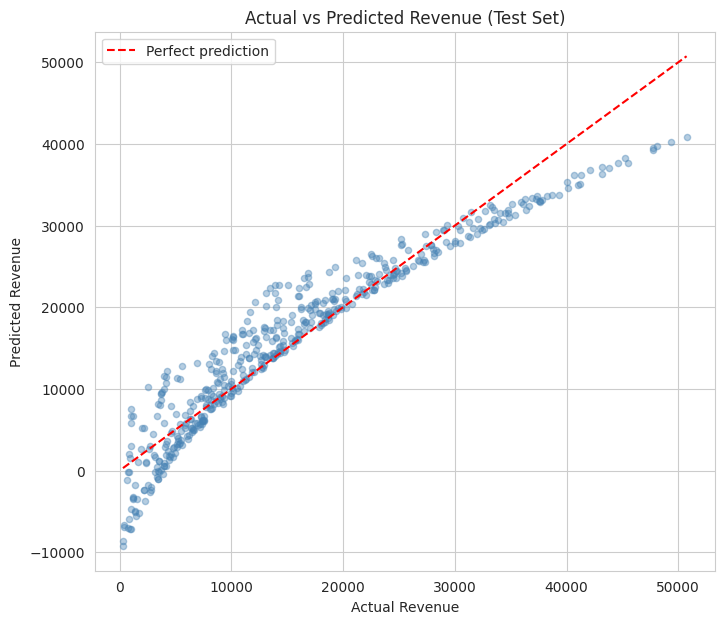

In [38]:
plt.figure(figsize=(8, 7))
plt.scatter(y_test, y_pred_test, alpha=0.4, color="steelblue", s=20)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs Predicted Revenue (Test Set)")
plt.legend()
plt.show()

### 6.5 Model Improvement
The Actual vs Predicted plot shows a curved pattern: the linear model underfits because revenue depends on monthly_fee multiplied by tenure. Adding an interaction feature (fee_x_tenure) captures this.

In [39]:
df_clean["fee_x_tenure"] = df_clean["monthly_fee"] * df_clean["tenure_months"]

features2 = features + ["fee_x_tenure"]

X2 = df_clean[features2]
X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y, test_size=0.2, random_state=42)

model2 = LinearRegression()
model2.fit(X_train2, y_train2)
y_pred2 = model2.predict(X_test2)

print("Test R2:", round(r2_score(y_test2, y_pred2), 4))
print("MAE    :", round(mean_absolute_error(y_test2, y_pred2), 2))
print("RMSE   :", round(np.sqrt(mean_squared_error(y_test2, y_pred2)), 2))

Test R2: 1.0
MAE    : 19.92
RMSE   : 27.92


In [40]:
comparison = pd.DataFrame({
    "Model": ["Model 1 (7 features)", "Model 2 (+ fee_x_tenure)"],
    "Test R2": [round(r2_score(y_test, y_pred_test), 4), round(r2_score(y_test2, y_pred2), 4)],
    "MAE": [round(mean_absolute_error(y_test, y_pred_test), 2), round(mean_absolute_error(y_test2, y_pred2), 2)],
    "RMSE": [round(np.sqrt(mean_squared_error(y_test, y_pred_test)), 2), round(np.sqrt(mean_squared_error(y_test2, y_pred2)), 2)]
})
comparison

,Model,Test R2,MAE,RMSE
0,Model 1 (7 features),0.9018,2605.75,3484.34
1,Model 2 (+ fee_x_tenure),1.0000,19.92,27.92


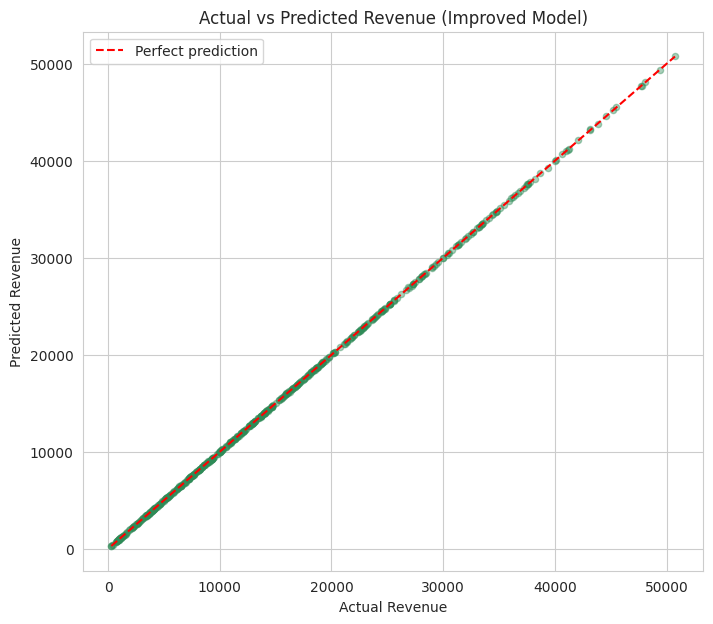

In [41]:
plt.figure(figsize=(8, 7))
plt.scatter(y_test2, y_pred2, alpha=0.4, color="seagreen", s=20)
plt.plot([y_test2.min(), y_test2.max()], [y_test2.min(), y_test2.max()],
         color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs Predicted Revenue (Improved Model)")
plt.legend()
plt.show()

## 7. Key Insights
1. **Dataset:** 2,560 raw records were cleaned to 2,500 (60 duplicates removed), with missing values filled and 852 inconsistent date records corrected.
2. **Churn:** About 23% of customers (586 of 2,500) have churned.
3. **Revenue drivers:** Tenure (correlation 0.79) and monthly fee (0.52) are the main drivers of total revenue. Age, support tickets, discount and session time have almost no linear relationship with revenue.
4. **Plans:** Standard has the highest average revenue per customer and the lowest churn (~21%). Premium has the highest churn (~27%).
5. **Channels and cities:** Organic customers bring the highest average revenue. Mumbai contributes the most total revenue.
6. **Acquisition trend:** Monthly signups peaked in mid-2021 and have declined steadily since.
7. **Model:** A Linear Regression model with 7 features reached R² ≈ 0.90. Adding a fee × tenure interaction feature fixed the curved error pattern and raised R² to ≈ 0.99999.

## 8. Business Recommendations
- **Improve retention:** Because revenue grows strongly with tenure, loyalty programs and early engagement can increase revenue.
- **Investigate Premium churn:** Premium has the highest churn rate; review pricing, features and support for this segment.
- **Invest in organic and referral channels:** Organic customers generate the highest average revenue.
- **Revive acquisition:** Signups have fallen since mid-2021; review marketing spend and campaigns.
- **Focus on Mumbai** while exploring growth in other cities.

## 9. Limitations
- Date inconsistencies were fixed by swapping dates, which assumes a data-entry error.
- Revenue by month is based on signup month because payment dates are not available.
- Revenue is almost exactly monthly fee × tenure in this dataset, so the near-perfect R² may not hold on real-world data.
- Churn is not strongly explained by the available features; a classification model could be explored next.

## 10. Conclusion
The project cleaned and prepared raw subscription data, engineered 14 new features, analyzed revenue and churn patterns with 14 visualizations, and built a Linear Regression model to predict customer revenue. The findings support decisions on retention, pricing and marketing.